In [20]:
import numpy as np
import cv2 as cv
from matplotlib import pyplot as plt

Реализуйте высокочастотную фильтрацию на основе ядра Гаусса

In [25]:
image = cv.imread('periodic_noise.JPG', cv.IMREAD_GRAYSCALE)

dft = cv.dft(np.float32(image), flags=cv.DFT_COMPLEX_OUTPUT)
dft_shifted = np.fft.fftshift(dft)

sigma = 20.0
rows, cols = image.shape
crow, ccol = rows // 2, cols // 2

u = np.arange(rows)
v = np.arange(cols)
U, V = np.meshgrid(u - crow, v - ccol, indexing='ij')

gaussian_low_pass = np.exp(-(U**2 + V**2) / (2 * sigma**2))
gaussian_high_pass = 1 - gaussian_low_pass

filtered_dft = dft_shifted * gaussian_high_pass[:, :, np.newaxis]
f_ishift = np.fft.ifftshift(filtered_dft)
img_back = cv.idft(f_ishift)
img_high_pass = cv.magnitude(img_back[:, :, 0], img_back[:, :, 1])

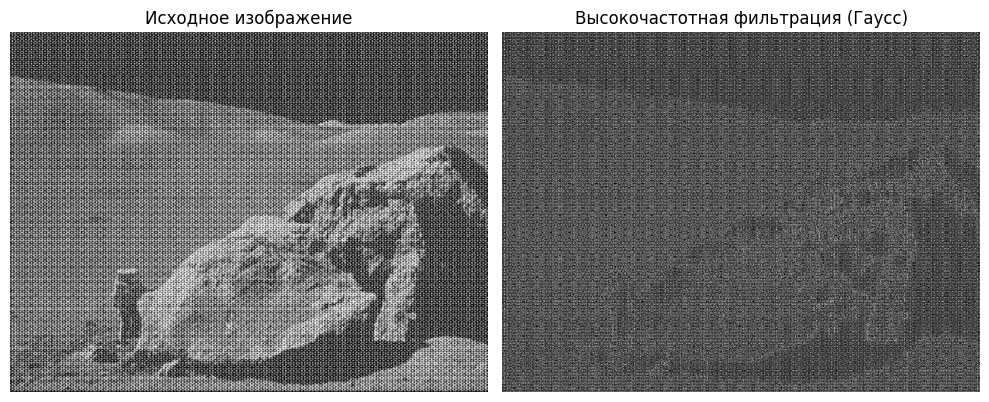

In [26]:
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(image, cmap='gray')
plt.title('Исходное изображение')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(img_high_pass, cmap='gray')
plt.title('Высокочастотная фильтрация (Гаусс)')
plt.axis('off')

plt.tight_layout()
plt.show()

Реализуйте вычисление свертки с помощью преобразования Фурье

In [29]:
img = cv.imread('periodic_noise.JPG', cv.IMREAD_GRAYSCALE)
img_float = np.float32(img)
rows, cols = img_float.shape

kernel_size = 15
kernel_1d = cv.getGaussianKernel(kernel_size, 0)
kernel_2d = np.outer(kernel_1d, kernel_1d)

padded_kernel = np.zeros_like(img_float)
padded_kernel[:kernel_size, :kernel_size] = kernel_2d

dft_image = np.fft.fft2(img_float)
dft_kernel = np.fft.fft2(padded_kernel)
spectrum_product = dft_image * dft_kernel
result_fft = np.real(np.fft.ifft2(spectrum_product))

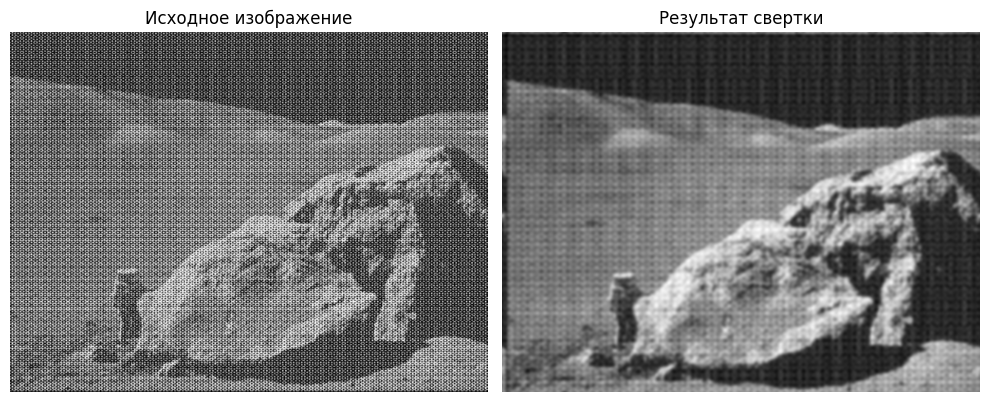

In [31]:
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(img, cmap='gray')
plt.title('Исходное изображение')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(result_fft, cmap='gray')
plt.title('Результат свертки')
plt.axis('off')

plt.tight_layout()
plt.show()

Реализуйте удаление периодического шума с помощью преобразования Фурье


In [33]:
img = cv.imread('periodic_noise.JPG', cv.IMREAD_GRAYSCALE)

dft = cv.dft(np.float32(img), flags=cv.DFT_COMPLEX_OUTPUT)
dft_shift = np.fft.fftshift(dft)
rows, cols = img.shape
crow, ccol = rows // 2, cols // 2

mask = np.ones((rows, cols, 2), np.uint8)
magnitude_spectrum = cv.magnitude(dft_shift[:, :, 0], dft_shift[:, :, 1])

temp_magnitude = magnitude_spectrum.copy()
temp_magnitude[crow-40:crow+40, ccol-40:ccol+40] = 0

threshold = np.mean(temp_magnitude) + 5 * np.std(temp_magnitude)
noise_peaks = np.argwhere(temp_magnitude > threshold)

peak_radius = 5
for y, x in noise_peaks:
    mask[max(0, y-peak_radius):min(rows, y+peak_radius+1),
         max(0, x-peak_radius):min(cols, x+peak_radius+1), :] = 0

    y_sym = rows - 1 - y
    x_sym = cols - 1 - x
    mask[max(0, y_sym-peak_radius):min(rows, y_sym+peak_radius+1),
         max(0, x_sym-peak_radius):min(cols, x_sym+peak_radius+1), :] = 0

filtered_dft_shift = dft_shift * mask
f_ishift = np.fft.ifftshift(filtered_dft_shift)
img_back = cv.idft(f_ishift)
img_cleaned = cv.magnitude(img_back[:, :, 0], img_back[:, :, 1])

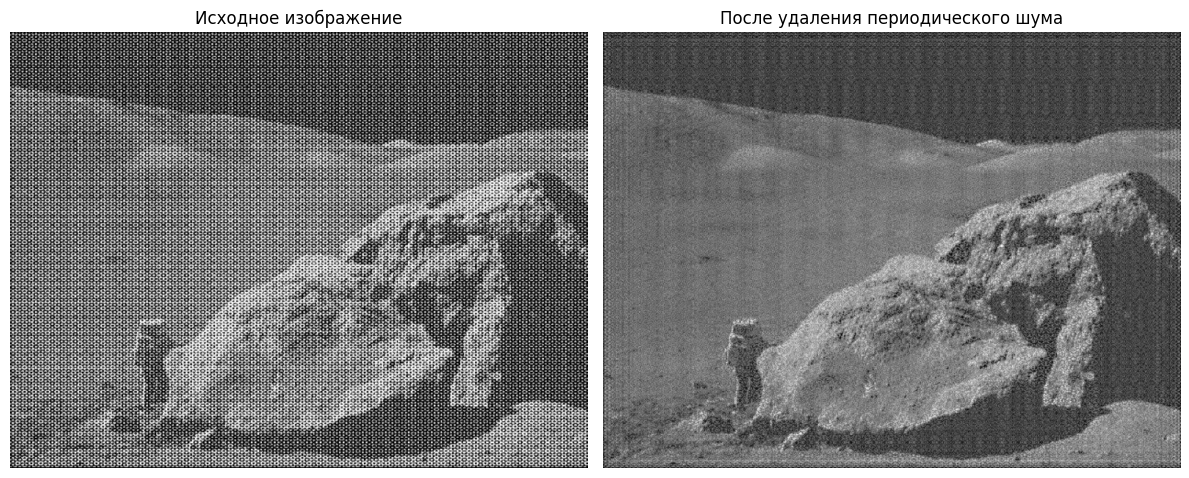

In [34]:
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(img, cmap='gray')
plt.title('Исходное изображение')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(img_cleaned, cmap='gray')
plt.title('После удаления периодического шума')
plt.axis('off')

plt.tight_layout()
plt.show()